# Piste 4 — Segmenter les flottes par usage (clustering)

**Question métier :** parmi les clients diesel, lesquels utilisent déjà leurs camions d'une façon compatible avec l'électrique ?

> ⚠️ **Données simulées.** Aucune donnée client de DAF n'est publique. Les profils d'usage sont générés ici pour **démontrer la méthode** : comme on connaît les vrais profils cachés, on peut vérifier que le K-means les retrouve.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- DONNÉES SIMULÉES (pour démontrer la méthode) ----------
rng = np.random.default_rng(42)

# 4 usages types, cachés au modèle : on vérifiera ensuite s'il les retrouve
profils = {
    #                 km/jour  arrêts/jour  % autoroute  charge (t)  retour dépôt
    "Livraison urbaine":   (120,  25, 0.10,  6, 0.95),
    "Distribution régionale": (280,  10, 0.45, 12, 0.85),
    "Longue distance":     (650,   3, 0.85, 22, 0.15),
    "Chantier / BTP":      (90,   12, 0.05, 25, 0.90),
}
poids = [0.30, 0.30, 0.25, 0.15]

lignes = []
for i in range(2000):
    nom = rng.choice(list(profils), p=poids)
    km, arrets, auto, charge, depot = profils[nom]
    km_moy = max(20, rng.normal(km, km * 0.20))
    lignes.append({
        "client": f"C{rng.integers(1, 151):03d}",        # 150 clients
        "km_jour_moyen": km_moy,
        "km_jour_max": km_moy * rng.uniform(1.15, 1.6),
        "arrets_jour": max(0, rng.normal(arrets, arrets * 0.25)),
        "part_autoroute": np.clip(rng.normal(auto, 0.08), 0, 1),
        "charge_moyenne_t": max(1, rng.normal(charge, charge * 0.2)),
        "part_retour_depot": np.clip(rng.normal(depot, 0.07), 0, 1),
        "profil_cache": nom,
    })
camions = pd.DataFrame(lignes)
print(camions.shape)
camions.head()

(2000, 8)


,client,km_jour_moyen,km_jour_max,arrets_jour,part_autoroute,charge_moyenne_t,part_retour_depot,profil_cache
0,C065,514.802066,753.575302,1.536724,0.745826,22.562498,0.127863,Longue distance
1,C129,99.526946,131.062965,29.861200,0.105282,7.352689,0.982726,Livraison urbaine
2,C134,128.850019,196.165653,24.687963,0.085211,5.182885,1.000000,Livraison urbaine
3,C010,82.290099,101.841191,13.596928,0.079236,27.063663,0.930157,Chantier / BTP
4,C062,597.166048,786.292636,3.461985,0.940318,21.498631,0.091189,Longue distance


## Choisir le nombre de groupes k
Le K-means repose sur des distances : il faut **standardiser** les variables avant.

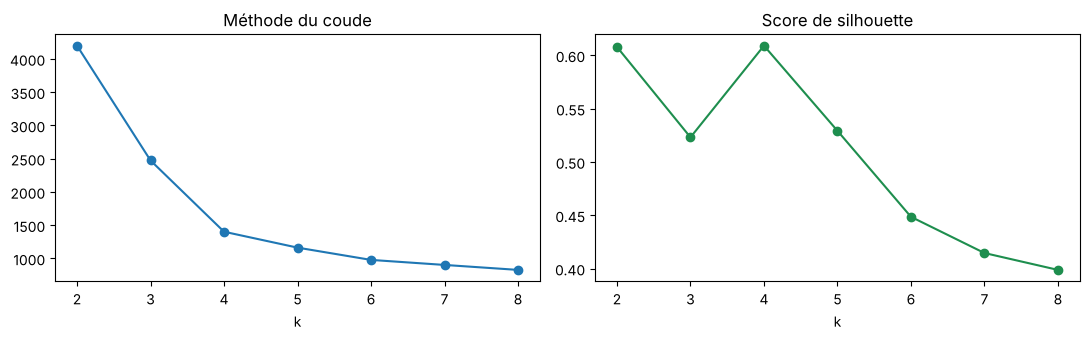

Meilleure silhouette pour k = 4


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

variables = ["km_jour_moyen", "km_jour_max", "arrets_jour",
             "part_autoroute", "charge_moyenne_t", "part_retour_depot"]
X = StandardScaler().fit_transform(camions[variables])   # obligatoire avant K-means

inerties, silhouettes = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ks, inerties, marker="o"); ax[0].set_title("Méthode du coude"); ax[0].set_xlabel("k")
ax[1].plot(ks, silhouettes, marker="o", color="#1e8e4e"); ax[1].set_title("Score de silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig("images/choix_k.png", dpi=150); plt.show()
print("Meilleure silhouette pour k =", list(ks)[int(np.argmax(silhouettes))])

Le coude est net à **k = 4**. La silhouette est presque à égalité entre k = 2 (« longue distance » contre « tout le reste ») et k = 4 : les scores aident, mais **le sens métier tranche**, et k = 2 serait inutile pour un commercial.

## Décrire les groupes et repérer les clients compatibles avec l'électrique

**Hypothèse électrique** (à affiner avec les fiches techniques réelles) : pire jour ≤ 300 km et retour au dépôt ≥ 80 % des jours (recharge la nuit).

                        km_jour_moyen  km_jour_max  arrets_jour  \
groupe                                                            
Longue distance                 650.9        893.6          3.0   
Livraison urbaine               119.5        164.3         24.5   
Chantier / BTP                   88.3        120.3         11.9   
Distribution régionale          279.4        384.5          9.9   

                        part_autoroute  charge_moyenne_t  part_retour_depot  
groupe                                                                       
Longue distance                    0.8              21.8                0.1  
Livraison urbaine                  0.1               6.0                0.9  
Chantier / BTP                     0.1              25.6                0.9  
Distribution régionale             0.4              12.0                0.9  

Accord avec les profils cachés (ARI, 1 = parfait) : 0.982

Part de camions compatibles électrique par groupe :
groupe_nom
Livrai

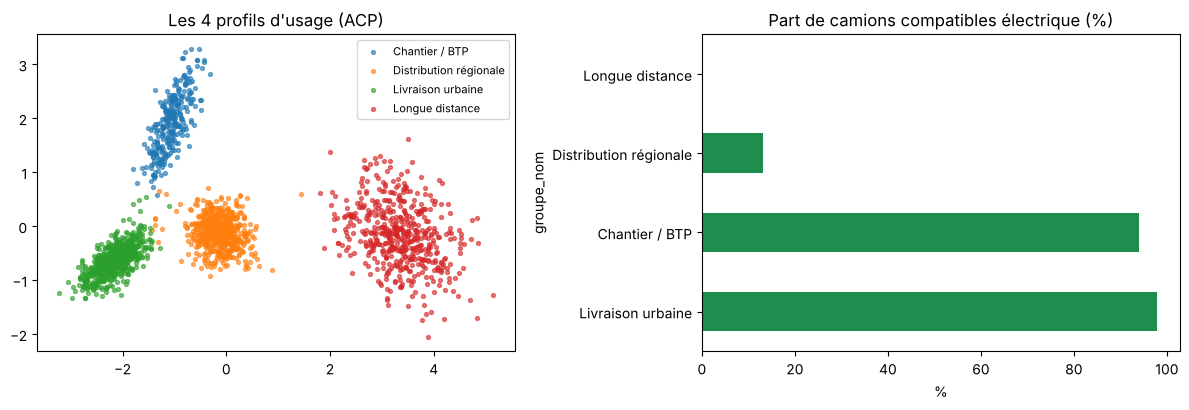


Top 10 des clients à cibler (au moins 10 camions) :
        nb_camions  part_compatible
client                             
C127            12             83.0
C030            11             82.0
C072            11             73.0
C029            11             73.0
C107            18             72.0
C092            14             71.0
C122            10             70.0
C064            13             69.0
C031            13             69.0
C022            13             69.0


In [3]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# 1. K-means final avec k = 4
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
camions["groupe"] = km4.labels_

# 2. Profil moyen de chaque groupe, et nom donné d'après ce profil
profil = camions.groupby("groupe")[variables].mean()
noms = {}
reste = list(profil.index)
for col, nom in [("km_jour_moyen", "Longue distance"), ("arrets_jour", "Livraison urbaine"),
                 ("charge_moyenne_t", "Chantier / BTP")]:
    g = profil.loc[reste, col].idxmax(); noms[g] = nom; reste.remove(g)
noms[reste[0]] = "Distribution régionale"
camions["groupe_nom"] = camions["groupe"].map(noms)
print(profil.rename(index=noms).round(1))

# 3. Vérification : le modèle a-t-il retrouvé les profils cachés ?
print("\nAccord avec les profils cachés (ARI, 1 = parfait) :",
      round(adjusted_rand_score(camions["profil_cache"], camions["groupe"]), 3))

# 4. Compatibilité électrique (hypothèse)
camions["compatible_electrique"] = (camions["km_jour_max"] <= 300) & (camions["part_retour_depot"] >= 0.8)
part = camions.groupby("groupe_nom")["compatible_electrique"].mean().sort_values(ascending=False)
print("\nPart de camions compatibles électrique par groupe :")
print((part * 100).round(1).astype(str) + " %")

# 5. Visualisation : les 4 groupes en 2D grâce à l'ACP
coords = PCA(n_components=2).fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for nom in sorted(camions["groupe_nom"].unique()):
    m = camions["groupe_nom"] == nom
    ax[0].scatter(coords[m, 0], coords[m, 1], s=8, label=nom, alpha=0.6)
ax[0].set_title("Les 4 profils d'usage (ACP)"); ax[0].legend(fontsize=8)
(part * 100).plot(kind="barh", ax=ax[1], color="#1e8e4e")
ax[1].set_title("Part de camions compatibles électrique (%)"); ax[1].set_xlabel("%")
plt.tight_layout(); plt.savefig("images/segments_electrique.png", dpi=150); plt.show()

# 6. Les clients à cibler en priorité
clients = camions.groupby("client").agg(nb_camions=("client", "size"),
                                        part_compatible=("compatible_electrique", "mean"))
cibles = clients[clients["nb_camions"] >= 10].sort_values("part_compatible", ascending=False)
print("\nTop 10 des clients à cibler (au moins 10 camions) :")
print(cibles.head(10).assign(part_compatible=lambda d: (d["part_compatible"] * 100).round(0)))

## Conclusions
- **ARI ≈ 0,98** : le K-means retrouve presque parfaitement les 4 profils cachés, la méthode est validée.
- Livraison urbaine et chantier sont très majoritairement compatibles avec l'électrique, la longue distance pas du tout : c'est là qu'il faut concentrer l'effort commercial.

**Limites :** données simulées ; dans la simulation, les camions sont répartis au hasard entre clients, donc la liste des clients illustre le format du livrable, pas un vrai ciblage ; le critère électrique ignore la charge utile (poids des batteries).